# Masking the recording fingerprint with shared noise

`recording_fingerprint.ipynb` showed that equalising every clip's average spectrum leaves the recording source
fully identifiable. One candidate for what survives is quiet, source-specific background: each source's own hiss,
ambience and codec gaps. This notebook tests a blunt fix: **add the same kind of noise to every clip**, at training
and at test time, so anything quieter than the noise is drowned out.

The risk is that quiet fault cues drown too. So the question is whether there is a noise level at which the source
becomes hard to identify while faults are still detectable.

Setup: frozen AST embeddings, logistic-regression classifiers, train split for fitting, validation split for scoring.
The test split is not used.

## 1. Setup and data

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import soundfile as sf
import torch
from huggingface_hub import snapshot_download
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, recall_score, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from transformers import ASTFeatureExtractor, ASTModel

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA_DIR = ROOT / "data" / "kwerimoto"
RESULTS_DIR = ROOT / "results"
CACHE_DIR = RESULTS_DIR / "cache"
FIG_DIR = RESULTS_DIR / "figures"
CACHE_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

MODEL_ID = "MIT/ast-finetuned-audioset-10-10-0.4593"
LABELS = ["healthy", "engine_knock", "misfire"]
HEALTHY, KNOCK, MISFIRE = 0, 1, 2
SR, CLIP_SAMPLES = 16_000, 160_000
SEED = 42
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

snapshot_download("rayyyyy007/kwerimoto-engine-sounds", repo_type="dataset", local_dir=DATA_DIR)
manifest = pd.read_csv(DATA_DIR / "manifest.csv")
manifest = manifest[manifest["split"].isin(["train", "validation"])].reset_index(drop=True)
y = manifest["label"].map({name: i for i, name in enumerate(LABELS)}).to_numpy()
source = manifest["source_dataset"].to_numpy()
tr = manifest.index[manifest["split"] == "train"].to_numpy()
va = manifest.index[manifest["split"] == "validation"].to_numpy()
waveforms = [sf.read(DATA_DIR / f, dtype="float32")[0] for f in manifest["file_name"]]

feature_extractor = ASTFeatureExtractor.from_pretrained(MODEL_ID)
ast = ASTModel.from_pretrained(MODEL_ID).to(DEVICE).eval()


@torch.inference_mode()
def embed(audios, name):
    """Frozen AST clip embeddings for a list of waveforms; cached on disk under `name`."""
    path = CACHE_DIR / f"noise_{name}.npy"
    if path.exists():
        return np.load(path)
    out = []
    for i in range(0, len(audios), 32):
        batch = feature_extractor(audios[i:i + 32], sampling_rate=SR, return_tensors="pt")
        out.append(ast(batch["input_values"].to(DEVICE)).pooler_output.float().cpu().numpy())
    out = np.concatenate(out)
    np.save(path, out)
    return out

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1074 files:   0%|          | 0/1074 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

[transformers] ASTModel LOAD REPORT from: MIT/ast-finetuned-audioset-10-10-0.4593
Key                         | Status     |  | 
----------------------------+------------+--+-
classifier.dense.bias       | UNEXPECTED |  | 
classifier.layernorm.weight | UNEXPECTED |  | 
classifier.layernorm.bias   | UNEXPECTED |  | 
classifier.dense.weight     | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


## 2. The masking recipe

For every clip:

1. *(optional, `eq`)* equalise the clip's long-term average spectrum to the training-set average, in the waveform.
   This is done **before** the noise so the noise itself is not re-coloured differently per clip.
2. Scale the clip to a common loudness.
3. Pad it to 10 s and add pink noise over the whole 10 s, at a chosen level relative to the clip.

The noise level is given as a signal-to-noise ratio (SNR): **20 dB** is faint hiss, **0 dB** means the noise is as loud
as the engine. `clean` applies steps 1–2 only. Each clip gets its own random noise, drawn from the same distribution.

In [2]:
N_FFT, HOP = 512, 160
WINDOW = torch.hann_window(N_FFT)
TARGET_RMS = 0.05


def stft(w):
    return torch.stft(torch.from_numpy(w), N_FFT, HOP, window=WINDOW, return_complex=True)


def average_spectrum(w):
    return torch.log(stft(w).abs().pow(2).mean(1) + 1e-10)


REFERENCE = torch.stack([average_spectrum(waveforms[i]) for i in tr]).mean(0)
MAX_GAIN = np.log(10 ** (40 / 20))  # limit correction to +-40 dB


def equalise(w):
    gain = (0.5 * (REFERENCE - average_spectrum(w))).clamp(-MAX_GAIN, MAX_GAIN).exp()[:, None]
    return torch.istft(stft(w) * gain, N_FFT, HOP, window=WINDOW, length=len(w)).numpy()


def pink_noise(n, rng):
    spectrum = np.fft.rfft(rng.standard_normal(n))
    spectrum[1:] /= np.sqrt(np.arange(1, len(spectrum)))
    noise = np.fft.irfft(spectrum, n)
    return (noise / np.sqrt((noise ** 2).mean())).astype(np.float32)


def mask(w, i, snr_db=None, eq=False):
    if eq:
        w = equalise(w)
    w = w * (TARGET_RMS / (np.sqrt((w ** 2).mean()) + 1e-8))
    if snr_db is None:
        return w.astype(np.float32)
    out = np.zeros(CLIP_SAMPLES, dtype=np.float32)
    out[:len(w)] = w[:CLIP_SAMPLES]
    return out + pink_noise(CLIP_SAMPLES, np.random.default_rng([SEED, i])) * TARGET_RMS * 10 ** (-snr_db / 20)


SNRS = [None, 20, 10, 5, 0]                      # None = clean
snr_name = lambda snr: "clean" if snr is None else f"{snr} dB"

embeddings = {("original", "—"): embed(waveforms, "original")}
for eq in (False, True):
    for snr in SNRS:
        key = ("eq + noise" if eq else "noise", snr_name(snr))
        embeddings[key] = embed([mask(w, i, snr, eq) for i, w in enumerate(waveforms)],
                                f"{'eq' if eq else 'raw'}_{snr_name(snr).replace(' ', '')}")
    print("done:", "eq + noise" if eq else "noise")

done: noise


done: eq + noise


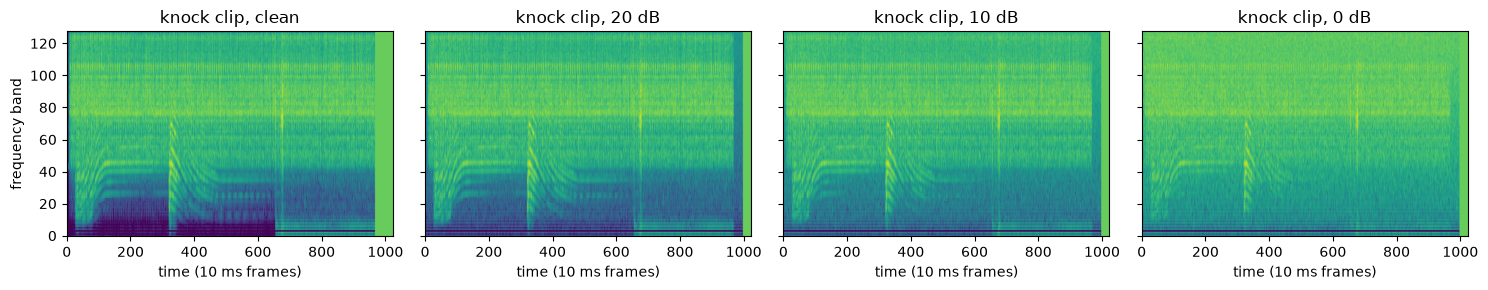

In [3]:
example = int(np.flatnonzero((source == "revix") & (manifest["duration_s"] > 9) & (y == KNOCK))[0])
fig, axes = plt.subplots(1, 4, figsize=(15, 3), sharey=True)
for ax, snr in zip(axes, [None, 20, 10, 0]):
    spec = feature_extractor(mask(waveforms[example], example, snr), sampling_rate=SR, return_tensors="np")["input_values"][0]
    ax.imshow(spec.T, origin="lower", aspect="auto", vmin=-1.3, vmax=1.0)
    ax.set(title=f"knock clip, {snr_name(snr)}", xlabel="time (10 ms frames)")
axes[0].set_ylabel("frequency band")
plt.tight_layout()
plt.savefig(FIG_DIR / "noise_examples.png", dpi=200, bbox_inches="tight")
plt.show()

## 3. Scoring

Same measures as `recording_fingerprint.ipynb`. Classifiers are trained and tested on clips with the **same**
treatment.

- **Source probe** (lower is better, 0.5 = chance): can a classifier tell the two sources of one class apart?
- **Fault recall / false alarm**: 3-class validation metrics.
- **Within-source AUC**: fault vs healthy with the source held fixed.
- **Confounded → clean**: train on AudioSet knocks vs Hugging Face healthy clips only, test on Revix knocks vs Revix
  healthy clips. Near 0.5 means the model learned the source, not the knock. ± is a bootstrap standard deviation.

In [4]:
def fit_predict(F_train, t_train, F_val):
    clf = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
    return clf.fit(F_train, t_train).predict_proba(F_val)


def source_probe(F, label):
    rtr, rva = tr[y[tr] == label], va[y[va] == label]
    proba = fit_predict(F[rtr], source[rtr], F[rva])
    return balanced_accuracy_score(source[rva], np.unique(source[rtr])[proba.argmax(1)])


def transfer_auc(F, train_mask, test_mask, n_boot=1000):
    rtr, rva = tr[train_mask(tr)], va[test_mask(va)]
    score = fit_predict(F[rtr], y[rtr] == KNOCK, F[rva])[:, 1]
    target = y[rva] == KNOCK
    rng, boots = np.random.default_rng(SEED), []
    for _ in range(n_boot):
        idx = rng.integers(0, len(rva), len(rva))
        if target[idx].min() != target[idx].max():
            boots.append(roc_auc_score(target[idx], score[idx]))
    return roc_auc_score(target, score), float(np.std(boots))


confounded = lambda r: ((source[r] == "audioset") & (y[r] == KNOCK)) | ((source[r] == "huggingface") & (y[r] == HEALTHY))
revix_only = lambda r: (source[r] == "revix") & np.isin(y[r], [HEALTHY, KNOCK])


def score(F):
    proba = fit_predict(F[tr], y[tr], F[va])
    pred = proba.argmax(1)
    recall = recall_score(y[va], pred, labels=[0, 1, 2], average=None, zero_division=0)
    out = {"source probe | healthy": source_probe(F, HEALTHY), "source probe | knock": source_probe(F, KNOCK),
           "fault recall": recall[1:].mean(), "false alarm": (pred[y[va] == HEALTHY] != HEALTHY).mean()}
    for name, (src, fault) in {"AUC knock | Revix": ("revix", KNOCK), "AUC misfire | HF": ("huggingface", MISFIRE)}.items():
        rows = (source[va] == src) & np.isin(y[va], [HEALTHY, fault])
        out[name] = roc_auc_score(y[va][rows] == fault, proba[rows, fault])
    out["confounded → clean"], out["± (c→c)"] = transfer_auc(F, confounded, revix_only)
    out["Revix → other"], out["± (R→o)"] = transfer_auc(F, revix_only, confounded)
    return out


results = pd.DataFrame({key: score(F) for key, F in embeddings.items()}).T
results.index.names = ["treatment", "noise level"]
results.to_csv(RESULTS_DIR / "noise_masking.csv")
results.round(3)

source probe | healthy  source probe | knock  \
treatment  noise level                                                 
original   —                             1.000                 0.907   
noise      clean                         1.000                 0.919   
           20 dB                         1.000                 0.942   
           10 dB                         1.000                 0.907   
           5 dB                          1.000                 0.895   
           0 dB                          0.988                 0.907   
eq + noise clean                         1.000                 0.930   
           20 dB                         1.000                 0.942   
           10 dB                         1.000                 0.953   
           5 dB                          1.000                 0.930   
           0 dB                          1.000                 0.884   

                        fault recall  false alarm  AUC knock | Revix  \
treatment  noise level                                                 
original   —                   0.770        0.192              0.860   
noise      clean               0.807        0.250              0.848   
           20 dB               0.819        0.173              0.851   
           10 dB               0.788        0.269              0.859   
           5 dB                0.799        0.192              0.826   
           0 dB                0.782        0.346              0.815   
eq + noise clean               0.762        0.212              0.817   
           20 dB               0.782        0.250              0.818   
           10 dB               0.819        0.154              0.856   
           5 dB                0.796        0.231              0.828   
           0 dB                0.722        0.269              0.778   

                        AUC misfire | HF  confounded → clean  ± (c→c)  \
treatment  noise level                                                  
original   —                       0.844               0.415    0.065   
noise      clean                   0.891               0.381    0.063   
           20 dB                   0.885               0.427    0.063   
           10 dB                   0.885               0.417    0.061   
           5 dB                    0.885               0.428    0.061   
           0 dB                    0.812               0.492    0.062   
eq + noise clean                   0.880               0.497    0.068   
           20 dB                   0.812               0.495    0.064   
           10 dB                   0.818               0.501    0.063   
           5 dB                    0.844               0.474    0.063   
           0 dB                    0.786               0.436    0.062   

                        Revix → other  ± (R→o)  
treatment  noise level                          
original   —                    0.455    0.075  
noise      clean                0.469    0.082  
           20 dB                0.320    0.069  
           10 dB                0.335    0.073  
           5 dB                 0.310    0.067  
           0 dB                 0.297    0.071  
eq + noise clean                0.665    0.093  
           20 dB                0.551    0.084  
           10 dB                0.528    0.084  
           5 dB                 0.500    0.082  
           0 dB                 0.548    0.091

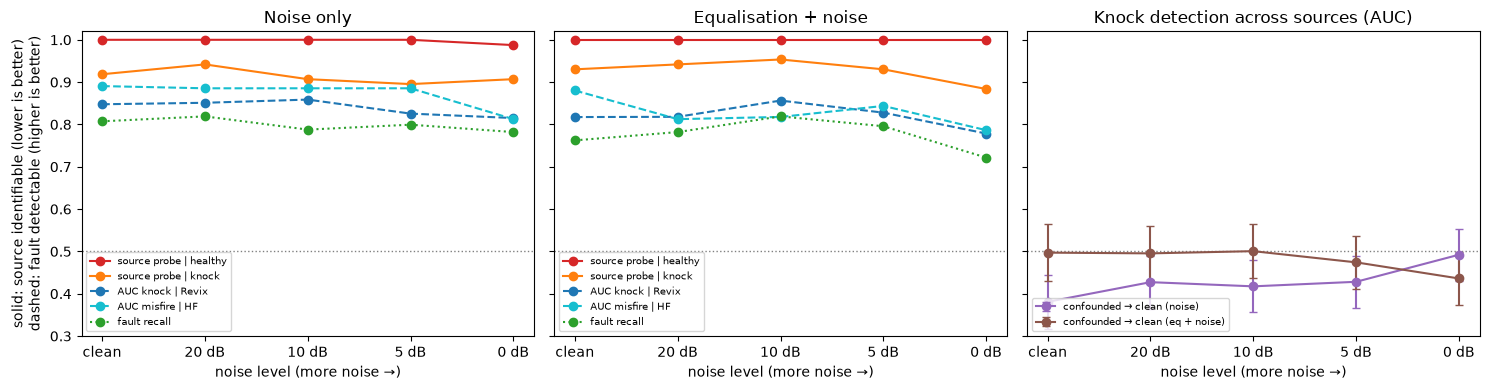

In [5]:
levels = [snr_name(s) for s in SNRS]
fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
panels = [
    ("Noise only", "noise", ["source probe | healthy", "source probe | knock", "AUC knock | Revix", "AUC misfire | HF", "fault recall"]),
    ("Equalisation + noise", "eq + noise", ["source probe | healthy", "source probe | knock", "AUC knock | Revix", "AUC misfire | HF", "fault recall"]),
]
styles = {"source probe | healthy": ("tab:red", "-"), "source probe | knock": ("tab:orange", "-"),
          "AUC knock | Revix": ("tab:blue", "--"), "AUC misfire | HF": ("tab:cyan", "--"), "fault recall": ("tab:green", ":")}
for ax, (title, treatment, cols) in zip(axes, panels):
    for col in cols:
        color, ls = styles[col]
        ax.plot(levels, results.loc[treatment].loc[levels, col], marker="o", color=color, ls=ls, label=col)
    ax.set(title=title, xlabel="noise level (more noise →)", ylim=(0.3, 1.02))
for treatment, color in [("noise", "tab:purple"), ("eq + noise", "tab:brown")]:
    block = results.loc[treatment].loc[levels]
    axes[2].errorbar(levels, block["confounded → clean"], yerr=block["± (c→c)"], marker="o", capsize=3,
                     color=color, label=f"confounded → clean ({treatment})")
axes[2].set(title="Knock detection across sources (AUC)", xlabel="noise level (more noise →)")
for ax in axes:
    ax.axhline(0.5, color="grey", ls=":", lw=1)
    ax.legend(fontsize=7, loc="lower left")
axes[0].set_ylabel("solid: source identifiable (lower is better)\ndashed: fault detectable (higher is better)")
plt.tight_layout()
plt.savefig(FIG_DIR / "noise_masking.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. What we found (draft)

**Shared noise did not hide the source, even when the noise was as loud as the engine.**

1. **The source stays identifiable at every noise level.** Healthy-clip sources are told apart with 99–100 %
   accuracy from clean down to 0 dB, and knock sources with about 90 %. Combining equalisation with noise changes
   nothing.
2. **Fault detection degrades slowly, and before the source does.** Within-source knock AUC falls from 0.86 to
   0.82 at 0 dB (0.78 with equalisation); misfire AUC from about 0.88 to 0.81. So there is no noise level where the
   source is hidden but the fault is still audible: the fault cues weaken first.
3. **Knock detection still does not transfer between sources.** Confounded → clean stays between 0.38 and 0.50 in
   every condition. The single higher value in the other direction (Revix → other, 0.67 ± 0.09 for equalisation
   without noise) is one point less than two standard deviations from chance and is not repeated at any noise
   level, so we do not read it as an effect.

**What this tells us.** If the fingerprint were quiet background (hiss, ambience, codec gaps), noise at 0 dB would
have buried it. It did not, so what identifies the source is in the loud part of the signal: the engines and
recording situations themselves differ between sources. Together with `recording_fingerprint.ipynb` (equalising tone
colour also failed), this rules out the two simplest recording-artefact explanations for KweriMoto. In this dataset
the "fingerprint" is mostly **what was recorded**, not how, and no input-side masking can separate that from the
fault label.

**Caveats.** One frozen model (AST), synthetic pink noise only, small validation sets, and a single noise draw per
clip. Whether shared noise helps against a genuine device fingerprint is still open: that needs data where the same
sound is recorded on different devices, which is what `device_shortcuts.ipynb` simulates.
